# Sample data access from NCAR's GDEX

For best results, we recommend first creating a new conda environment using the included code/environment.yml file in the top-level directory of this repository using:

```
conda env create -f environment.yml
# or
mamba env create -f environment.yml
```

We also recommend downloading the `bcd_me_helper_pack.zip` file from the GitHub repository, at [this link](https://github.com/ks905383/bcd_me/blob/main/bcd_me_helper_pack.zip?raw=True), which includes a few useful functions for specifically working with the GDEX stores, stored in the `bcd_me_helpers` module referenced below.

The paths to the BCD-ME data on NCAR's GDEX are available on the dataset's page [here](https://gdex.ucar.edu/datasets/d164444/). 

This data access guide assumes access to the NCAR HPC system (which may be [available](https://ncar-hpc-docs.readthedocs.io/en/latest/allocations/university-allocations/#small-allocations) to you even if you are not an NCAR employee). If you do not have access to the NCAR HPC system, you can directly download the data using the links in the GDEX page above, though given the size of the dataset, you may want to consider accessing it on the cloud through Earthmover instead (see the `sample_data_access_earthmover.ipynb` notebook in the same directory). 

Note that due to the more permanent nature of the GDEX store, bugs are more likely to persist than in the Earthmover version (see `sample_data_access_earthmover.ipynb` for details in accessing data from the Earthmover Marketplace). These are documented on the [GitHub](https://github.com/ks905383/bcd_me/) as they are found, and we include a helper function (detailed below) to easily nan out affected BCD-ME members.

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import warnings

from matplotlib import pyplot as plt
import matplotlib as mpl
import cartopy
from cartopy import crs as ccrs
import cmocean

from bcd_me_helpers import modlists,filter_problems

The BCD-ME is stored in zarr stores, separately by data type and by ESM. The BCD-ME on GDEX is located at paths of the form: 

```
https://boreas.hpc.ucar.edu:6443/gdex-data/d164444/bcd_me/bcd_me_[data-type]_[ESM-name].zarr
```

Three types of data are offered: 
- 1$^\circ$ time series by GWL (`[data-type] = 'qdm'`)
- 0.25$^\circ$ statistics of time series by GWL (`[data-type] = 'qdm-qplad'`)
- 1$^\circ$ time series by year (`[data-type] = 'qdm-byyr'`)

Note that `qdm-byyr` data are an extension of the BCD-ME methodology documented in an upcoming paper rather than in the BCD-ME data descriptor. They are a set of SSP2-4.5 runs organized in 20-year chunks by model calendar year rather than by GWL, for sets of comparisons that incorporate climate sensitivity differences between ESMs. 

We can use `modlists` from `bcd_me_helpers` to list which ESMs have data available for each data type:

In [2]:
print(f'Models available for 1-deg time series by GWL / qdm : \n{modlists['qdm']} \n')
print(f'Models available for 0.25-deg time series statistics by GWL / qdm-qplad : \n{modlists['qdm-qplad']}\n')
print(f'Models available for 1-deg time series statistics by year / qdm-qplad : \n{modlists['qdm-qplad']}\n')

Models available for 1-deg time series by GWL / qdm : 
['ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'BCC-ESM1', 'CAMS-CSM1-0', 'CESM2-WACCM', 'CMCC-CM2-SR5', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'CanESM5', 'EC-Earth3', 'EC-Earth3-Veg', 'FGOALS-g3', 'IITM-ESM', 'IPSL-CM6A-LR', 'MIROC-ES2L', 'MIROC6', 'MPI-ESM-1-2-HAM', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NESM3'] 

Models available for 0.25-deg time series statistics by GWL / qdm-qplad : 
['ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'BCC-ESM1', 'CAMS-CSM1-0', 'CESM2-WACCM', 'CMCC-CM2-SR5', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'CanESM5', 'EC-Earth3', 'EC-Earth3-Veg', 'FGOALS-g3', 'IITM-ESM', 'IPSL-CM6A-LR', 'MIROC-ES2L', 'MIROC6', 'MPI-ESM-1-2-HAM', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NESM3']

Models available for 1-deg time series statistics by year / qdm-qplad : 
['ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'BCC-ESM1', 'CAMS-CSM1-0', 'CESM2-WACCM', 'CMCC-CM2-SR5', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'CanESM5', 'EC-Earth3',

## Accessing 1$^\circ$ bias-corrected time series 

Let's open a set of ACCESS-ESM1-5 time series data, so that `[data-type] = 'qdm'` and `[ESM-name] = 'ACCESS-ESM1-5'`. ACCESS-ESM1-5 is one of the "Large Ensembles" with data in the BCD-ME, i.e., an ESM with data from many ensemble members. 

In [3]:
data_type = 'qdm'
esm = 'ACCESS-ESM1-5'

ds = xr.open_zarr(f'https://boreas.hpc.ucar.edu:6443/gdex-data/d164444/bcd_me/bcd_me_{data_type}_{esm}.zarr')
ds

<xarray.Dataset> Size: 6TB
Dimensions:                         (idv: 25, proj_base: 5, lat: 142, lon: 360,
                                     gwl: 8, dayofyear: 365, year: 20,
                                     variable: 2)
Coordinates: (12/13)
    experiment                      (idv) <U6 600B dask.array<chunksize=(25,), meta=np.ndarray>
    model                           (idv) <U13 1kB dask.array<chunksize=(25,), meta=np.ndarray>
    run                             (idv) <U9 900B dask.array<chunksize=(25,), meta=np.ndarray>
  * proj_base                       (proj_base) <U6 120B 'ERA5' ... 'PRISM'
  * lat                             (lat) float64 1kB -55.5 -54.5 ... 84.5 85.5
  * lon                             (lon) float64 3kB -179.5 -178.5 ... 179.5
    ...                              ...
    flag_has_data                   (variable, idv, gwl) bool 400B dask.array<chunksize=(2, 25, 8), meta=np.ndarray>
    flag_has_historical_duplicates  (idv, gwl) bool 200B dask.array<chunksize=(25, 8), meta=np.ndarray>
  * dayofyear                       (dayofyear) int64 3kB 1 2 3 ... 363 364 365
  * year                            (year) int64 160B 1 2 3 4 5 ... 17 18 19 20
    calendar_year                   (idv, gwl, year) float64 32kB dask.array<chunksize=(25, 8, 20), meta=np.ndarray>
  * variable                        (variable) object 16B 'tas' 'tasmax'
Dimensions without coordinates: idv
Data variables:
    tas                             (idv, proj_base, lat, lon, gwl, dayofyear, year) float64 3TB dask.array<chunksize=(1, 1, 40, 40, 1, 365, 20), meta=np.ndarray>
    tasmax                          (idv, proj_base, lat, lon, gwl, dayofyear, year) float64 3TB dask.array<chunksize=(1, 1, 40, 40, 1, 365, 20), meta=np.ndarray>
Attributes:
    DESCRIPTION:  ACCESS-ESM1-5 ScenarioMIP runs, bias-corrected using Quanti...
    Project:      Bias-Corrected, Downscaled Massive Ensemble (BCD-ME)
    Creators:     Kevin Schwarzwald, Nathan Lenssen, Radley Horton, and Gerno...
    Version:      v1.0
    License:      CC BY 4.0 (for proj_base == ERA5, MERRA-2, or GMFD), CC BY-...

### Filter out members with data issues
We try to keep the BCD-ME as clean as possible, but bugs happen. We list known bugs in the BCD-ME on the main [GitHub page](https://github.com/ks905383/bcd_me/) and document them in the [Issues]() tab of the same page (please help us out by opening Issues when you run into new ones!). 

We update the cloud version on Earthmover as soon as we can, but due to the nature of the data store, bugs may persist for longer on GDEX. The `filter_problems()` function from the `bcd_me_helpers` file allows easy filtering out (by setting them to nan) of affected BCD-ME members.  

`filter_problems()` works on any subset of the BCD-ME, so, for example, one bias-corrected model's data, all bias-corrected models' data, or some subset of either, as long as the `idv` variable is kept. 

In [8]:
from bcd_me_helpers import filter_problems
ds = filter_problems(ds,
                      flagged_members=None, # to automatically download up-to-date problem lists
                      verbose=True,
                      )

SHA256 hash of downloaded file: 215070f387f6d4ca7a5b60b5e7bb3cd97010b46d9e5cfa51d9345bfb9a973ec4
Use this value as the 'known_hash' argument of 'pooch.retrieve' to ensure that the file hasn't changed if it is downloaded again in the future.
Unzipping contents of '/glade/u/home/schwarzwald/.cache/problem_members/8abbc16f249047b9e7674b070352dd49-bcd_me_problem_members.zip' to '/glade/u/home/schwarzwald/.cache/problem_members/8abbc16f249047b9e7674b070352dd49-bcd_me_problem_members.zip.unzip'


Assuming target data is from the `qdm` BCD-ME set...
Found problem members in variables: tas (2 members); they (or their derivatives) will be replaced with nans.
Filtering matched variables tas.


## Accessing 0.25$^\circ$ downscaled statistics

Now, let's take a look at the statistics of the downscaled data at 0.25-degrees in the BCD-ME. In this example, we'll also look at all BCD-ME members at once, focusing on just the grid cell closest to New York City. 

In [9]:
modlists['qdm-qplad']

# Let's access all "`qdm-qplad`", i.e. downscaled statistics, stores
with warnings.catch_warnings():
    # Silences increaseing chunk warning
    warnings.filterwarnings('ignore')
    dss = xr.concat([xr.open_zarr(f'https://boreas.hpc.ucar.edu:6443/gdex-data/d164444/bcd_me/bcd_me_qdm-qplad_{esm}.zarr',
                              decode_timedelta=False)
                for esm in modlists['qdm-qplad']],
                dim='idv',join='outer')

# Let's also filter out any known problem members 
dss = filter_problems(dss,verbose=True)

Assuming target data is from the `qdm-qplad` BCD-ME set...
Found problem members in variables: tas (8 members), tasmax (6 members); they (or their derivatives) will be replaced with nans.
Filtering matched variables tasbinC, tasbinF, tasmaxbinC, tasmaxbinF, tasmaxsumpoly, tassumpoly.


In [10]:
# Let's look at days > 90 F around New York City
ds = dss['tasbinF'].sel(lat=40,lon=-74,method='nearest').load()

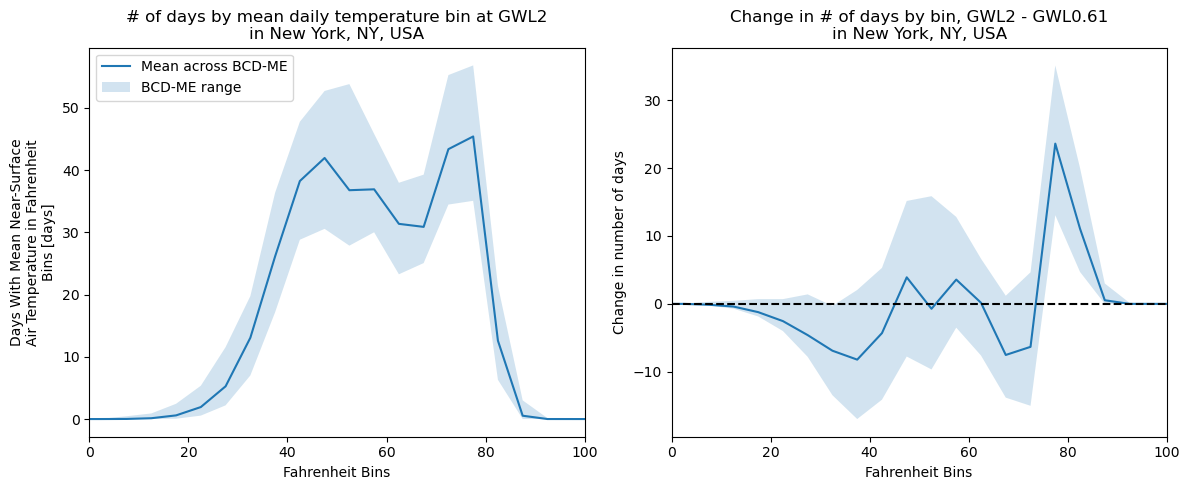

In [16]:
fig = plt.figure(figsize=(12,5))
ax = plt.subplot(1,2,1)
plot_data = ds.sel(gwl=2,proj_base='ERA5')
plot_data.mean('idv').plot(label='Mean across BCD-ME')
ax.fill_between(plot_data.binF,
                plot_data.min('idv'),
                plot_data.max('idv'),
                alpha=0.2,label='BCD-ME range')
ax.set_xlim([0,100])
ax.set_title('# of days by mean daily temperature bin at GWL2\nin New York, NY, USA')
ax.legend()

ax = plt.subplot(1,2,2)
plot_data = (ds.sel(gwl=2,proj_base='ERA5') - 
             ds.sel(gwl=0.61,proj_base='ERA5'))
plot_data.mean('idv').plot(label='Mean across BCD-ME')
ax.fill_between(plot_data.binF,
                plot_data.min('idv'),
                plot_data.max('idv'),
                alpha=0.2,label='BCD-ME range')
ax.set_title('Change in # of days by bin, GWL2 - GWL0.61\nin New York, NY, USA')
ax.set_ylabel('Change in number of days')
ax.axhline(0,color='k',linestyle='--')
ax.set_xlim([0,100])

plt.tight_layout()

Let's now get the number of days with mean temperature above 80 degrees, track its projected change by GWL, and partition the uncertainty in this projected change into contributions from reanalysis choice (as "ground truth" for bias correction and downscaling), model uncertainty, and internal variability. 

We'll use the Law of Total Variance to partition the spread across the BCD-ME in these sources -- note that this isn't quite exact (for one, the Law of Total Variance assumes complete separability of these sources, but model and internal variability are certainly correlated, for example, since ESMs have different internal variabilities), but is a common assumption that holds up in many cases (see, e.g., the discussion in [Lehner et al., 2020](https://esd.copernicus.org/articles/11/491/2020/)). 

In [61]:
# Now, get change in number of days with mean temperature > 80
# skipna=False is crucial! Otherwise nans / missing data will register as 0s
dds = ds.sel(binF = slice(80,None)).sum('binF',skipna=False)
dds = dds - dds.sel(gwl=0.61)
dds = dds.compute()

In [62]:
# How many runs should a model have to be included in calculation?
min_runs = 7

# Keep only "balanced" panel across GWLs, i.e., runs that reach desired max GWL
gwl_max = 2.5
dds_sub = dds.where((~np.isnan(dds.sel(gwl=gwl_max))).all('proj_base'))
dds_sub = dds_sub.sel(gwl=slice(0,gwl_max))

In [63]:
# Partition uncertainty using Law of Total Variance

dds_sub['exprun'] = dds_sub['experiment']+dds_sub['run']
dds_sub = dds_sub.set_index(idv = ['model','exprun']).unstack()

# Get number of runs by model 
runs_by_mod = (~dds_sub.isnull()).sum('exprun').isel(proj_base=0,gwl=0,drop=True)
dds_sub = dds_sub.where(runs_by_mod >= min_runs,drop=True)
print(f'Using {dds_sub.sizes['model']} models...')

# Subset by models with more than X runs

uncerts = xr.merge([dds_sub.var('proj_base').mean('exprun').mean('model').to_dataset(name='uncobs'),
          dds_sub.mean('proj_base').var('exprun').mean('model').to_dataset(name='uncint'),
          dds_sub.mean('proj_base').mean('exprun').var('model').to_dataset(name='uncmod')])
uncerts = xr.concat([uncerts,
                     uncerts / uncerts.to_dataarray().sum('variable')],
                    dim=pd.Index(['raw','norm'],name='typ'))

Using 12 models...


/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)


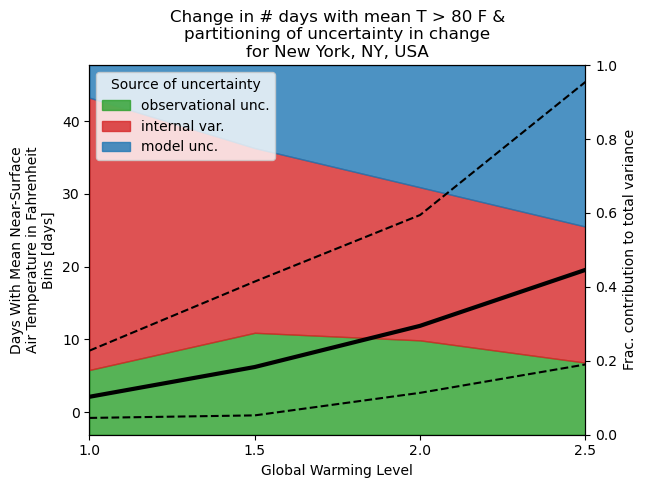

In [64]:

# Plot mean / min / max across BCD-ME first
ax = plt.subplot()

dds.mean(['proj_base','idv']).sel(gwl=slice(1,gwl_max)).plot(color='k',ax=ax,zorder=5,lw=3)
dds.min(['proj_base','idv']).sel(gwl=slice(1,gwl_max)).plot(color='k',linestyle='--',ax=ax)
dds.max(['proj_base','idv']).sel(gwl=slice(1,gwl_max)).plot(color='k',linestyle='--',ax=ax)

ax.set_title(('Change in # days with mean T > 80 F &\n'+
              'partitioning of uncertainty in change\n'+
              'for New York, NY, USA'))

# Now, plot partitioned uncertainty
ax2 = ax.twinx()
plot_data = uncerts.sel(typ='norm')
uncert_colors = {'uncmod':'tab:blue',
                 'uncint':'tab:red',
                 'uncobs':'tab:green'}
unc_source_names = {'uncint':'internal var.',
                                    'uncmod':'model unc.',
                                    'uncobs':'observational unc.',
                                    'uncreg':'regression unc.',
                                    'uncsce':'scenario unc.'}

varlist = [var for var in plot_data if var in uncert_colors]
xdim='gwl'
bottom = np.zeros(plot_data.sizes[xdim])
for var in varlist:
    plot_values = plot_data[var]

    ax2.fill_between(plot_values['gwl'],
                            bottom,
                            bottom + plot_values,
                            color = uncert_colors[var],
                            label = unc_source_names[var],alpha=0.8,zorder=1)
    bottom += plot_values
ax2.set_xlim([plot_data[xdim].values[1],plot_data[xdim].values[-1]])
ax2.set_ylim([0,1])

ax2.set_xlabel(r'GWL [$^\circ$C]')
ax2.set_ylabel('Frac. contribution to total variance')

ax2.legend(title='Source of uncertainty',loc='upper left')
ax2.set_zorder(0)

# Set order of plotting
ax.set_zorder(2)
ax.set_facecolor('none')

# Set xticks at locations of data
ax.set_xticks(plot_data.gwl.values[1:None])



## Accessing 1-degree data by year

On GDEX, we also provide a set of BCD-ME runs that are indexed by 20-year calendar year chunks (i.e., "2040-2060" in each ESM) instead of by GWL. These can provide a reference for how much intermodel differences in climate sensitivity (otherwise removed when showing data by GWL) affect intermodel uncertainty for a particular question. 

The `qdm-byyr` ensemble members are from ESM simulations that were run under the SSP2-4.5 experiment. 

Here is example code to show how much an estimate of model uncertainty (in changes in mean temperature in one location) changes when indexing by GWL rather than by calendar year. We compare changes between GWL0.61 and GWL1 to changes between 1982-2001 and 2000-2019, which roughly correspond to GWLs 0.61 and 1 in the real world, but have diverging GWLs in models due to differing climate sensitivities. 

In [66]:
# Let's access all "`qdm-byyr`", i.e. by calendar year timeseries, 
# and all "`qdm`", i.e. by GWL timeseries, to compare
with warnings.catch_warnings():
    # Silences increaseing chunk warning
    warnings.filterwarnings('ignore')
    dss = {typ:xr.concat([xr.open_zarr(f'https://boreas.hpc.ucar.edu:6443/gdex-data/d164444/bcd_me/bcd_me_{typ}_{esm}.zarr',
                              decode_timedelta=False)
                for esm in modlists[typ]],
                dim='idv',join='outer')
           for typ in ['qdm','qdm-byyr']}

# Let's just look at NYC again, for ease
dss = {typ:ds.sel(lat=40,lon=-74,method='nearest')
       for typ,ds in dss.items()}
# Let's also filter out any known problem members 
dss = {typ:filter_problems(ds,verbose=True)
       for typ,ds in dss.items()}

Assuming target data is from the `qdm` BCD-ME set...
Found problem members in variables: tas (8 members), tasmax (6 members); they (or their derivatives) will be replaced with nans.
Filtering matched variables tas, tasmax.
Assuming target data is from the `qdm-byyr` BCD-ME set...
Found problem members in variables: tas (7 members), tasmax (2 members); they (or their derivatives) will be replaced with nans.
Filtering matched variables tas, tasmax.


/glade/u/home/schwarzwald/projects/bcd_me_final/code/bcd_me_helpers.py:131: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  flags = xr.merge(flags)
/glade/u/home/schwarzwald/projects/bcd_me_final/code/bcd_me_helpers.py:131: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  flags = xr.merge(flags)
/glade/u/home/schwarzwald/projects/bcd_me_fi

In [68]:
for typ in dss:
    dss[typ] = dss[typ].set_index(idv = ['model','experiment','run'])

# Let's compare the same BCD-ME members
dss['qdm'] = dss['qdm'].sel(idv = dss['qdm-byyr'].idv.values)

In [81]:
# Let's compare mean changes between GWLs 0.61 and 1, and between 0.61 and 2000-2019 ("gwl == 2010" in the `byyr` files)
ddss = {'qdm':dss['qdm']['tas'].sel(gwl = 1).mean(('dayofyear','year')) - dss['qdm']['tas'].sel(gwl = 0.61).mean(('dayofyear','year')),
        'qdm-byyr':dss['qdm-byyr']['tas'].sel(gwl = 2010).mean(('dayofyear','year')) - dss['qdm-byyr']['tas'].sel(gwl = 0.61).mean(('dayofyear','year'))}

In [84]:
# Compute
ddss = {typ:ds.compute() for typ,ds in ddss.items()}

Text(0.5, 1.0, 'Spread across models for change in mean T in NYC')

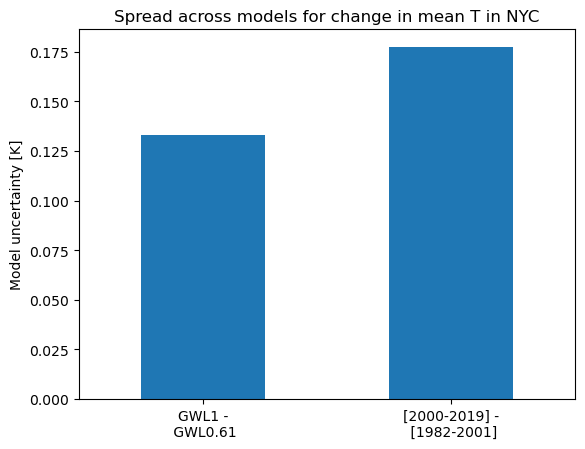

In [102]:
typs = ['qdm','qdm-byyr']
typ_names = {'qdm':'GWL1 -\n GWL0.61',
             'qdm-byyr':'[2000-2019] -\n [1982-2001]'}
ax = plt.subplot()
bar = plt.bar([1,2],
                      [ddss[typ].groupby('model').mean().mean('proj_base').std('model')
                       for typ in ['qdm','qdm-byyr']],width=0.5)
ax.set_xlim([0.5,2.5])
ax.set_xticks([1,2],
              [typ_names[typ] for typ in ddss])
ax.set_ylabel('Model uncertainty [K]')
ax.set_title('Spread across models for change in mean T in NYC')